## Impedance Match Known Hugoniots with Monte Carlo


In [1]:
#@title Double-click to collapse code
%matplotlib inline
import os
from os.path import exists

# necessary subdirectories
if not os.path.isdir('database-user/'):
    os.mkdir('database-user')
    print('made local directory: database-user')

# Collect files needed to run this notebook in the cloud (e.g., Google CoLab)
use_local_files = True # prefer local files than GitHub repo (change to false to refresh from repo)

if use_local_files:
    if not exists('materials-data.csv'):
        # material database
        print('missing file')
    if not exists('materials-new.csv'):
        # new material database entry
        print('missing file')
    if not exists('IM_module.py'):
        # IM_modules for this notebook
        print('missing file')
    if not exists('IM_app.py'):
        # IM_modules for this notebook
        print('missing file')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import os
from os.path import exists

# Impedance Match Calculation classes and functions
import IM_module as IM # classes and functions for this impedance match notebook
from scipy import linalg
from copy import deepcopy

In [2]:
# load the materials data table; change matfilename if not using default
matdata, imat = IM.ReadMaterials(matfilename='materials-data.csv')
# hopefully everything in mks
up =np.arange(501)/500*6000


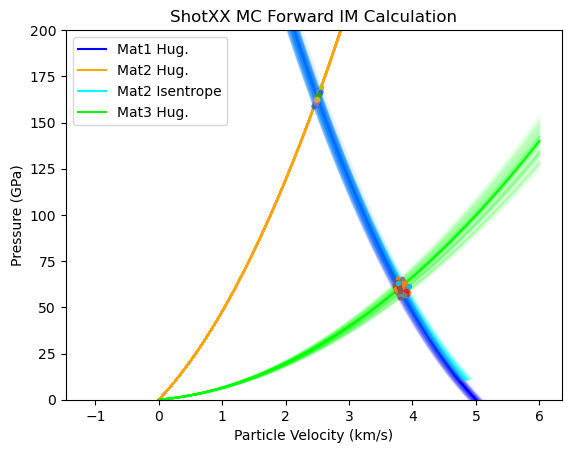

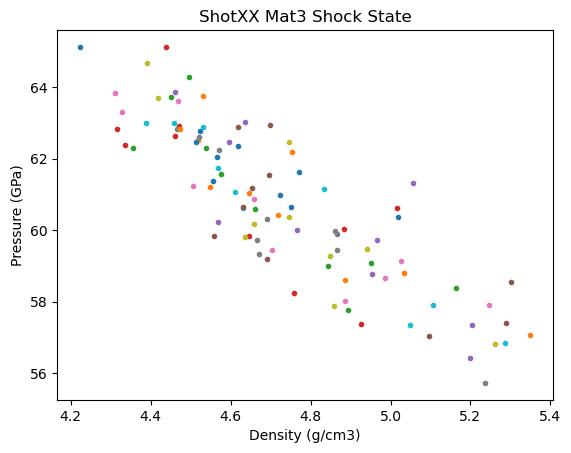

Forward IM Solution
ShotXX Steel304-l2 Steel304-l2 Fused-qtz-stv
Vimp =  5000 50
N= 100
Pressure mean, std (GPa) =  60.71755366585232 2.1616528442255865
Density mean, std (g/cm3) =  4.7304653318089045 0.26317613514560373
Up mean, std (km/s) =  3.8276933103440394 0.04578940424011861
Us mean, std (km/s) =  7.199077987401995 0.28823862516007476
 


In [4]:
SS304a = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
SS304a.DefineParamsID(matname,matdata,imat) # load the parameters for this material
SS304a.MakeHugoniot(up)
SS304a.rho0_err = 10

SS304b = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
SS304b.DefineParamsID(matname,matdata,imat) # load the parameters for this material
SS304b.MakeHugoniot(up)
SS304b.rho0_err = 10

FQstv = IM.Material() # create material object named 'mat3'
matname='Fused-qtz-stv' # material name in the material-data.csv file
FQstv.DefineParamsID(matname,matdata,imat) # load the parameters for this material
FQstv.MakeHugoniot(up)
FQstv.rho0_err = 10

## Write out the Monte Carlo Loop

# gather the covariance matrices
SS304a.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
SS304a.lmat = linalg.cholesky(SS304a.cov,lower=True)
SS304b.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
SS304b.lmat = linalg.cholesky(SS304b.cov,lower=True)
FQstv.cov = np.asarray([[ 0.0065196 , -0.02354445],[-0.02354445,  0.08556451]])
FQstv.lmat = linalg.cholesky(FQstv.cov,lower=True)

velpair = [5000,50]
#uspair = [6000,100]
uspair = [0,50]

N=100
#result = IM.MCIM('ShotXX',mat1,mat2,mat3,N,velpair,uspair,up,plots=True)
result = IM.MCIM('ShotXX',SS304a,SS304b,FQstv,N,velpair,uspair,up,plots=True)
print(result)

In [ ]:
print(result)

In [ ]:
vel=5000. # m/s
IM12_success = mat1.IM_match(mat2,vel=vel)
#IM23_success = mat2.IM_match(mat3,pstart=mat2.im1,usemgmodelbool=True,vel=vel)
IM23_success = mat2.IM_match(mat3,pstart=mat2.im1,usemgmodelbool=True,vel=vel)
#print(mat2.isen.parr/1.e9)

plt.plot((vel-mat1.hug.uparr)/1.e3,mat1.hug.parr/1.e9,label='Mat1 Hug.')
plt.plot(mat2.hug.uparr/1.e3,mat2.hug.parr/1.e9,label='Mat2 Hug.')
plt.plot(mat2.im1.up/1.e3,mat2.im1.p/1.e9,'D',color='black',label='IM Mat2')
plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,label='Mat2 Isentrope')
plt.plot(mat3.im1.up/1.e3,mat3.im1.p/1.e9,'D',label='IM Mat3')
plt.plot(mat3.hug.uparr/1.e3,mat3.hug.parr/1.e9,label='Mat3 Hug.')
plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,label='Mat3 RL')
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Pressure (GPa)')
plt.ylim([0,200])
plt.xlim([0,5.500])
plt.legend()

print(mat3.im1)

In [ ]:
## Write out the Monte Carlo Loop

# gather the uncertainties
# SS304 refit
mat1.rho0_err = 10
mat1.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
mat1.lmat = linalg.cholesky(mat1.cov,lower=True)
mat2.rho0_err = 10
mat2.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
mat2.lmat = linalg.cholesky(mat2.cov,lower=True)
mat3.rho0_err = 10
vel = 5000
vel_err = 50
c_us = 7000
c_us_err = 50

plt.plot((vel-mat1.hug.uparr)/1.e3,mat1.hug.parr/1.e9,label='Mat1 Hug.')
plt.plot(mat2.hug.uparr/1.e3,mat2.hug.parr/1.e9,label='Mat2 Hug.')
#plt.plot(mat2.im1.up/1.e3,mat2.im1.p/1.e9,'D',color='black',label='IM Mat2')
plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,label='Mat2 Isentrope')
#plt.plot(mat3.im1.up/1.e3,mat3.im1.p/1.e9,'D',label='IM Mat3')
plt.plot(mat3.hug.uparr/1.e3,mat3.hug.parr/1.e9,label='Mat3 Hug.')
#plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,label='Mat3 RL')
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Pressure (GPa)')
#plt.ylim([0,200])
#plt.xlim([0,5.500])
plt.legend()

MClist = []
for i in range(10):
    # make new MC object
    MCone = IM.MCstructure()
    # initialize flyer-> driver MC Hugoniots
    res1 = mat1.MakeHugoniotMC(up)
    res2 = mat2.MakeHugoniotMC(up)
    MCone.a_rho0=res1[0]
    MCone.a_c0=res1[1]
    MCone.a_s1=res1[2]
    MCone.b_rho0=res2[0]
    MCone.b_c0=res2[1]
    MCone.b_s1=res2[2]
    # initialize uncertainty in impact velocity
    veli = vel+vel_err*np.random.randn()
    MCone.vel = veli
    # solve for driver state
    IM12_success = mat1.IM_matchMC(mat2,vel=veli)
    MCone.up1=mat2.im1.up
    MCone.p1=mat2.im1.p
    MCone.us1=mat2.im1.us
    MCone.rho1=1/mat2.im1.v
    # initialize uncertainty in mat3 density
    mat3.hugmc.v0 = 1./(mat3.rho0+mat3.rho0_err*np.random.randn())
    MCone.c_rho0 = 1/mat3.hugmc.v0
    # initialize uncertainty in mat3 shock velocity
    c_usi = c_us+c_us_err*np.random.randn()
    MCone.c_us = c_usi
    # calculate Rayleigh line intersection
    IM23_success = mat2.IM_matchMC(mat3,pstart=mat2.im1,usemgmodelbool=True,vel=veli)
    MCone.up2=mat3.im1.up
    MCone.p2=mat3.im1.p
    MCone.us2=mat3.im1.us
    MCone.rho2=1/mat3.im1.v
    MClist.append(MCone)
    plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,color='cyan',alpha=0.05)
    plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,color='lime',alpha=0.05)

for MC in MClist:
    plt.plot(MC.up1/1.e3,MC.p1/1.e9,'.')
    plt.plot(MC.up2/1.e3,MC.p2/1.e9,'.')
plt.ylim([0,200])
plt.show()

plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
#plt.ylim([0,200])
#plt.xlim([0,5.500])
#plt.legend()

pall=[]
rall=[]
upall=[]
usall=[]
for MC in MClist:
    plt.plot(MC.rho2/1.e3,MC.p2/1.e9,'.')
    pall.append(MC.p2/1.e9)
    rall.append(MC.rho2/1.e3)
    upall.append(MC.up2/1.e3)
    usall.append(MC.us2/1.e3)
plt.show()

print('N=',len(MClist))
print('Pressure mean, std (GPa) = ',np.mean(pall),np.std(pall))
print('Density mean, std (g/cm3) = ',np.mean(rall),np.std(rall))
print('Up mean, std (km/s) = ',np.mean(upall),np.std(upall))
print('Us mean, std (km/s) = ',np.mean(usall),np.std(usall))



In [ ]:
stop

In [ ]:
## Write out the Monte Carlo Loop

# gather the uncertainties
# SS304 refit
mat1.rho0_err = 10
mat1.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
mat1.lmat = linalg.cholesky(mat1.cov,lower=True)
mat2.rho0_err = 10
mat2.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
mat2.lmat = linalg.cholesky(mat2.cov,lower=True)
mat3.rho0_err = 10
vel = 5000
vel_err = 50
c_us = 7000
c_us_err = 50

plt.plot((vel-mat1.hug.uparr)/1.e3,mat1.hug.parr/1.e9,label='Mat1 Hug.')
plt.plot(mat2.hug.uparr/1.e3,mat2.hug.parr/1.e9,label='Mat2 Hug.')
#plt.plot(mat2.im1.up/1.e3,mat2.im1.p/1.e9,'D',color='black',label='IM Mat2')
plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,label='Mat2 Isentrope')
#plt.plot(mat3.im1.up/1.e3,mat3.im1.p/1.e9,'D',label='IM Mat3')
#plt.plot(mat3.hug.uparr/1.e3,mat3.hug.parr/1.e9,label='Mat3 Hug.')
plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,label='Mat3 RL')
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Pressure (GPa)')
#plt.ylim([0,200])
#plt.xlim([0,5.500])
plt.legend()

MClist = []
for i in range(100):
    # make new MC object
    MCone = IM.MCstructure()
    # initialize flyer-> driver MC Hugoniots
    res1 = mat1.MakeHugoniotMC(up)
    res2 = mat2.MakeHugoniotMC(up)
    MCone.a_rho0=res1[0]
    MCone.a_c0=res1[1]
    MCone.a_s1=res1[2]
    MCone.b_rho0=res2[0]
    MCone.b_c0=res2[1]
    MCone.b_s1=res2[2]
    # initialize uncertainty in impact velocity
    veli = vel+vel_err*np.random.randn()
    MCone.vel = veli
    # solve for driver state
    IM12_success = mat1.IM_matchMC(mat2,vel=veli)
    MCone.up1=mat2.im1.up
    MCone.p1=mat2.im1.p
    MCone.us1=mat2.im1.us
    MCone.rho1=1/mat2.im1.v
    # initialize uncertainty in mat3 density
    mat3.hugmc.v0 = 1./(mat3.rho0+mat3.rho0_err*np.random.randn())
    MCone.c_rho0 = 1/mat3.hugmc.v0
    # initialize uncertainty in mat3 shock velocity
    c_usi = c_us+c_us_err*np.random.randn()
    MCone.c_us = c_usi
    # calculate Rayleigh line intersection
    IM23_success = mat2.IM_matchMC(mat3,pstart=mat2.im1,usemgmodelbool=True,vel=veli,rayleigh_us=c_usi)
    MCone.up2=mat3.im1.up
    MCone.p2=mat3.im1.p
    MCone.us2=mat3.im1.us
    MCone.rho2=1/mat3.im1.v
    MClist.append(MCone)
    plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,color='cyan',alpha=0.05)
    plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,color='lime',alpha=0.05)

for MC in MClist:
    plt.plot(MC.up1/1.e3,MC.p1/1.e9,'.')
    plt.plot(MC.up2/1.e3,MC.p2/1.e9,'.')

plt.show()

plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
#plt.ylim([0,200])
#plt.xlim([0,5.500])
#plt.legend()

pall=[]
rall=[]
for MC in MClist:
    plt.plot(MC.rho2/1.e3,MC.p2/1.e9,'.')
    pall.append(MC.p2/1.e9)
    rall.append(MC.rho2/1.e3)
plt.show()

print('N=',len(MClist))
print('Pressure mean, std (GPa) = ',np.mean(pall),np.std(pall))
print('Density mean, std (g/cm3) = ',np.mean(rall),np.std(rall))

In [ ]:
## Write out the Monte Carlo Loop

# gather the uncertainties
# SS304 refit
mat1.rho0_err = 10
mat1.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
mat1.lmat = linalg.cholesky(mat1.cov,lower=True)
mat2.rho0_err = 10
mat2.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
mat2.lmat = linalg.cholesky(mat2.cov,lower=True)
mat3.rho0_err = 10
vel = 5000
vel_err = 50
c_us = 7000
c_us_err = 50

plt.plot((vel-mat1.hug.uparr)/1.e3,mat1.hug.parr/1.e9,label='Mat1 Hug.')
plt.plot(mat2.hug.uparr/1.e3,mat2.hug.parr/1.e9,label='Mat2 Hug.')
#plt.plot(mat2.im1.up/1.e3,mat2.im1.p/1.e9,'D',color='black',label='IM Mat2')
plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,label='Mat2 Isentrope')
#plt.plot(mat3.im1.up/1.e3,mat3.im1.p/1.e9,'D',label='IM Mat3')
#plt.plot(mat3.hug.uparr/1.e3,mat3.hug.parr/1.e9,label='Mat3 Hug.')
plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,label='Mat3 RL')
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Pressure (GPa)')
#plt.ylim([0,200])
#plt.xlim([0,5.500])
plt.legend()

MClist = []
for i in range(1000):
    # make new MC object
    MCone = IM.MCstructure()
    # initialize flyer-> driver MC Hugoniots
    res1 = mat1.MakeHugoniotMC(up)
    res2 = mat2.MakeHugoniotMC(up)
    MCone.a_rho0=res1[0]
    MCone.a_c0=res1[1]
    MCone.a_s1=res1[2]
    MCone.b_rho0=res2[0]
    MCone.b_c0=res2[1]
    MCone.b_s1=res2[2]
    # initialize uncertainty in impact velocity
    veli = vel+vel_err*np.random.randn()
    MCone.vel = veli
    # solve for driver state
    IM12_success = mat1.IM_matchMC(mat2,vel=veli)
    MCone.up1=mat2.im1.up
    MCone.p1=mat2.im1.p
    MCone.us1=mat2.im1.us
    MCone.rho1=1/mat2.im1.v
    # initialize uncertainty in mat3 density
    mat3.hugmc.v0 = 1./(mat3.rho0+mat3.rho0_err*np.random.randn())
    MCone.c_rho0 = 1/mat3.hugmc.v0
    # initialize uncertainty in mat3 shock velocity
    c_usi = c_us+c_us_err*np.random.randn()
    MCone.c_us = c_usi
    # calculate Rayleigh line intersection
    IM23_success = mat2.IM_matchMC(mat3,pstart=mat2.im1,usemgmodelbool=True,vel=veli,rayleigh_us=c_usi)
    MCone.up2=mat3.im1.up
    MCone.p2=mat3.im1.p
    MCone.us2=mat3.im1.us
    MCone.rho2=1/mat3.im1.v
    MClist.append(MCone)
    plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,color='cyan',alpha=0.05)
    plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,color='lime',alpha=0.05)

for MC in MClist:
    plt.plot(MC.up1/1.e3,MC.p1/1.e9,'.')
    plt.plot(MC.up2/1.e3,MC.p2/1.e9,'.')

plt.show()

plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
#plt.ylim([0,200])
#plt.xlim([0,5.500])
#plt.legend()

pall=[]
rall=[]
for MC in MClist:
    plt.plot(MC.rho2/1.e3,MC.p2/1.e9,'.')
    pall.append(MC.p2/1.e9)
    rall.append(MC.rho2/1.e3)
plt.show()

print('N=',len(MClist))
print('Pressure mean, std (GPa) = ',np.mean(pall),np.std(pall))
print('Density mean, std (g/cm3) = ',np.mean(rall),np.std(rall))

In [ ]:
## Write out the Monte Carlo Loop

# gather the uncertainties
# SS304 refit
mat1.rho0_err = 10
mat1.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
mat1.lmat = linalg.cholesky(mat1.cov,lower=True)
mat2.rho0_err = 10
mat2.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
mat2.lmat = linalg.cholesky(mat2.cov,lower=True)
mat3.rho0_err = 10
vel = 5000
vel_err = 50
c_us = 7000
c_us_err = 50

plt.plot((vel-mat1.hug.uparr)/1.e3,mat1.hug.parr/1.e9,label='Mat1 Hug.')
plt.plot(mat2.hug.uparr/1.e3,mat2.hug.parr/1.e9,label='Mat2 Hug.')
#plt.plot(mat2.im1.up/1.e3,mat2.im1.p/1.e9,'D',color='black',label='IM Mat2')
plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,label='Mat2 Isentrope')
#plt.plot(mat3.im1.up/1.e3,mat3.im1.p/1.e9,'D',label='IM Mat3')
#plt.plot(mat3.hug.uparr/1.e3,mat3.hug.parr/1.e9,label='Mat3 Hug.')
plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,label='Mat3 RL')
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Pressure (GPa)')
#plt.ylim([0,200])
#plt.xlim([0,5.500])
plt.legend()

MClist = []
for i in range(2000):
    # make new MC object
    MCone = IM.MCstructure()
    # initialize flyer-> driver MC Hugoniots
    res1 = mat1.MakeHugoniotMC(up)
    res2 = mat2.MakeHugoniotMC(up)
    MCone.a_rho0=res1[0]
    MCone.a_c0=res1[1]
    MCone.a_s1=res1[2]
    MCone.b_rho0=res2[0]
    MCone.b_c0=res2[1]
    MCone.b_s1=res2[2]
    # initialize uncertainty in impact velocity
    veli = vel+vel_err*np.random.randn()
    MCone.vel = veli
    # solve for driver state
    IM12_success = mat1.IM_matchMC(mat2,vel=veli)
    MCone.up1=mat2.im1.up
    MCone.p1=mat2.im1.p
    MCone.us1=mat2.im1.us
    MCone.rho1=1/mat2.im1.v
    # initialize uncertainty in mat3 density
    mat3.hugmc.v0 = 1./(mat3.rho0+mat3.rho0_err*np.random.randn())
    MCone.c_rho0 = 1/mat3.hugmc.v0
    # initialize uncertainty in mat3 shock velocity
    c_usi = c_us+c_us_err*np.random.randn()
    MCone.c_us = c_usi
    # calculate Rayleigh line intersection
    IM23_success = mat2.IM_matchMC(mat3,pstart=mat2.im1,usemgmodelbool=True,vel=veli,rayleigh_us=c_usi)
    MCone.up2=mat3.im1.up
    MCone.p2=mat3.im1.p
    MCone.us2=mat3.im1.us
    MCone.rho2=1/mat3.im1.v
    MClist.append(MCone)
    plt.plot((2*mat2.im1.up-mat2.isen.uparr)/1e3,mat2.isen.parr/1.e9,color='cyan',alpha=0.05)
    plt.plot(mat3.rayleigh.uparr/1.e3,mat3.rayleigh.parr/1.e9,color='lime',alpha=0.05)

for MC in MClist:
    plt.plot(MC.up1/1.e3,MC.p1/1.e9,'.')
    plt.plot(MC.up2/1.e3,MC.p2/1.e9,'.')

plt.show()

plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
#plt.ylim([0,200])
#plt.xlim([0,5.500])
#plt.legend()

pall=[]
rall=[]
for MC in MClist:
    plt.plot(MC.rho2/1.e3,MC.p2/1.e9,'.')
    pall.append(MC.p2/1.e9)
    rall.append(MC.rho2/1.e3)
plt.show()

print('N=',len(MClist))
print('Pressure mean, std (GPa) = ',np.mean(pall),np.std(pall))
print('Density mean, std (g/cm3) = ',np.mean(rall),np.std(rall))

In [ ]:
# old code
print(sio2dat.iloc[0])

list=sio2dat.loc[:,["shot"]]
print(list)
row = np.where(list == 48)[0]
print(row)
print(sio2dat.loc[row,:])
us=sio2dat.loc[row,'us']

mat3 = deepcopy(QTZcacl2)
print(mat3.rho0)
